<a href="https://colab.research.google.com/github/victor836768/piv_chess/blob/main/notebooks/etapa2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
from google.colab import drive
import csv
import os
import json
import pandas as pd
from PIL import Image, ImageOps
from collections import defaultdict
import matplotlib.pyplot as plt

#ens connectem al drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive/')

drive_path = '/content/drive/MyDrive/PIV PROJECT V2'
data_zip = f'{drive_path}/data/raw/Dataset.v2i.coco.zip'
models_dir = f'{drive_path}/models'
resultats_dir = f'{drive_path}/resultats'
local_data_dir = '/content/local_data'

if not os.path.exists('/content/local_data'):
    print("Descomprimint dataset...")
    !unzip -oq "{data_zip}" -d "{local_data_dir}"
    print("Dataset descomprimit correctament!")
else:
    print("El dataset ja estava descomprimit a /content/local_data. Saltant aquest pas.")

versio_manifest = "v1"
manifest_dir = f'{drive_path}/resultats/particions_manifest_{versio_manifest}.csv'
df_manifest = pd.read_csv(manifest_dir)

# Baixem el codi del repo dins de la màquina virtual de Colab
!git clone https://github.com/victor836768/piv_chess
%cd piv_chess

VERSIO = "v1"
html_out_path= os.path.join(resultats_dir, f"resum_classificador_informe_{VERSIO}.html")
linies_informe = []
imatges_informe = []

def registrar(text=""):
    text_str = str(text)
    print(text_str)
    linies_informe.append(text_str)

# Mostrar les primeres 5 files i el recompte per partició
registrar(df_manifest.head())
registrar("\nRecompte per partició:")
registrar(df_manifest["split"].value_counts())

# Convertir a diccionari {file_name: split} per fer-lo servir al codi:
file_to_split = dict(zip(df_manifest["file_name"], df_manifest["split"]))


El dataset ja estava descomprimit a /content/local_data. Saltant aquest pas.
Cloning into 'piv_chess'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 37 (delta 7), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 1.58 MiB | 33.71 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess/piv_chess
                                           file_name group  split
0  G072_IMG089_jpg.rf.790412fc30620b4cd7711d406dd...  G072    val
1  G061_IMG098_jpg.rf.dda45cb89591a09cd1e0d580545...  G061  train
2  G028_IMG089_jpg.rf.dc3dc223b5ef066efffaebd7741...  G028    val
3  G091_IMG045_jpg.rf.01a539e5c55e5dad07634eef429...  G091  train
4  G019_IMG044_jpg.rf.ba1187d9c220145ee5ba9bfa109...  G019  train

Recompte per partició:
split
train    1470
val       311
test    

In [36]:
def pad_to_square(img, fill_color=(114, 114, 114)):
    w, h = img.size
    max_side = max(w, h)
    pad_left = (max_side - w) // 2
    pad_top = (max_side - h) // 2
    pad_right = max_side - w - pad_left
    pad_bottom = max_side - h - pad_top
    return ImageOps.expand(img, (pad_left, pad_top, pad_right, pad_bottom), fill=fill_color)



 Paquet de retalls trobat a /content/drive/MyDrive/PIV PROJECT V2/data/processed/retalls_96x96.zip. Descomprimint...

Retalls preparats! Total: 43142 peces
   - Train: 30840 | Val: 6527 | Test: 5775


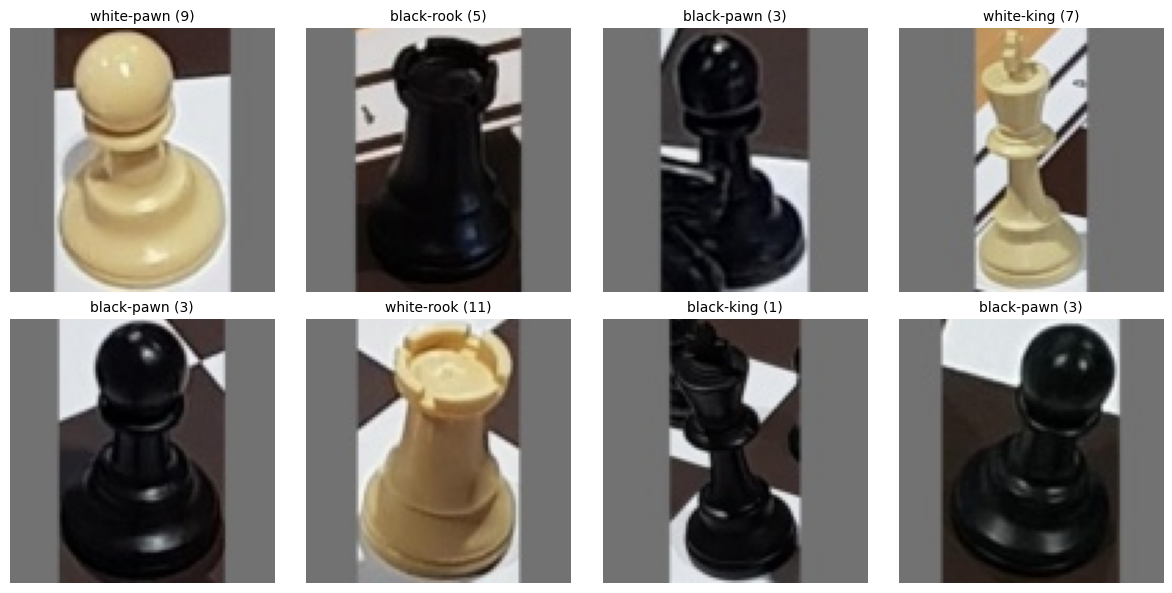

In [39]:
#1. preparem rutes
json_dir = f'{local_data_dir}/train/_annotations.coco.json'
imatges_dir = f'{local_data_dir}/train/'

retalls_dir = "/content/local_data/local_retalls/"
manifest_retalls_local = os.path.join(retalls_dir, "retalls_manifest.csv")

if not os.path.exists(retalls_dir):
    os.makedirs(retalls_dir, exist_ok=True)

processed_dir = f"{drive_path}/data/processed"

TARGET_SIZE = (96, 96)
zip_retalls_drive = (
    f"{processed_dir}/retalls_{TARGET_SIZE[0]}x{TARGET_SIZE[1]}.zip"
)

#llegirem el json, on ens diu la classe dels retalls
with open(json_dir, "r", encoding="utf-8") as f:
  coco = json.load(f)

active_cats = [cat for cat in coco["categories"] if cat["id"] != 0]
sorted_cats = sorted(active_cats, key=lambda x: x["id"])
cat_id_to_idx = {cat["id"]: idx for idx, cat in enumerate(sorted_cats)}
idx_to_label = {idx: cat["name"] for idx, cat in enumerate(sorted_cats)}

#3. farem un for per cada anotacio del manifest de la db original per a fer el retall i el noou manifest del retall i crearem el zip si no existeix.

if os.path.exists(zip_retalls_drive):
  print(
      f"\n Paquet de retalls trobat a {zip_retalls_drive}. Descomprimint..."
  )
  os.makedirs(retalls_dir, exist_ok=True)
  !unzip -oq "{zip_retalls_drive}" -d /
  df_crops = pd.read_csv(manifest_retalls_local)
else:
  print("\n Generant retalls per primera vegada (pot trigar uns segons)...")
  os.makedirs(retalls_dir, exist_ok=True)

  images_info = {img["id"]: img for img in coco["images"]}
  manifest_retalls = []

  # Agrupem anotacions per foto per obrir cada imatge una sola vegada
  anotacions_per_foto = defaultdict(list)
  for ann in coco["annotations"]:
    if ann["category_id"] in cat_id_to_idx:
      anotacions_per_foto[ann["image_id"]].append(ann)

  # Recorrem cada foto un sol cop
  for image_id, llista_anns in anotacions_per_foto.items():
    img_info = images_info[image_id]
    fname = img_info["file_name"]
    img_path = os.path.join(imatges_dir, fname)

    if not os.path.exists(img_path) or fname not in file_to_split:
      continue

    with Image.open(img_path) as img:
      img = img.convert("RGB")
      for ann in llista_anns:
        x, y, w, h = map(int, ann["bbox"])
        if w <= 2 or h <= 2:
          continue

        # RETALLAR -> PADDING -> RESIZE
        crop = img.crop((
            max(0, x),
            max(0, y),
            min(img.width, x + w),
            min(img.height, y + h),
        ))
        crop_sq = pad_to_square(crop)
        crop_resized = crop_sq.resize(TARGET_SIZE, Image.Resampling.BILINEAR)

        crop_save_path = os.path.join(retalls_dir, f"crop_{ann['id']}.jpg")
        crop_resized.save(crop_save_path, quality=95)

        manifest_retalls.append({
            "crop_path": crop_save_path,
            "label_idx": cat_id_to_idx[ann["category_id"]],
            "label_name": idx_to_label[cat_id_to_idx[ann["category_id"]]],
            "split": file_to_split[fname],
        })

  # Guardem el manifest local i empaquetem cap al Drive
  df_crops = pd.DataFrame(manifest_retalls)
  df_crops.to_csv(manifest_retalls_local, index=False)

  print(f" Comprimint retalls cap al Drive: {zip_retalls_drive}")
  !zip -rq "{zip_retalls_drive}" "{retalls_dir}"

df_train = df_crops[df_crops["split"] == "train"].reset_index(drop=True)
df_val = df_crops[df_crops["split"] == "val"].reset_index(drop=True)
df_test = df_crops[df_crops["split"] == "test"].reset_index(drop=True)

registrar(f"\nRetalls preparats! Total: {len(df_crops)} peces")
registrar(
    f"   - Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}"
)

#ensenyarem uns 8 retalls ja preparats per entrar a la cnn
mostra = df_train.sample(8)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, fila) in zip(axes.flat, mostra.iterrows()):
  img = Image.open(fila['crop_path'])
  ax.imshow(img)
  ax.set_title(f"{fila['label_name']} ({fila['label_idx']})", fontsize=10)
  ax.axis('off')

plt.tight_layout()
plt.show()


In [34]:
with open(html_out_path, "w", encoding="utf-8") as f:
  f.write(
      "<html><head><meta charset='utf-8'></head><body"
      " style='font-family:sans-serif; padding:20px;'>\n"
  )
  f.write(
      "<pre style='background:#f4f4f4; padding:15px; border-radius:8px;"
      " font-size:14px;'>\n"
  )
  f.write("\n".join(linies_informe))
  f.write("\n</pre>\n<hr>\n")
  f.write("\n".join(imatges_informe))
  f.write("\n</body></html>")

print(f"✅ HTML desat correctament amb {len(imatges_informe)} imatges a: {html_out_path}")

✅ HTML desat correctament amb 0 imatges a: /content/drive/MyDrive/PIV PROJECT V2/resultats/resum_classificador_informe_v1.html
